# Forward sensitivity and identifiability

**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.

## Objectives

Trace the evidence from source contract to result. State units and assumptions, reproduce the calculation, and identify which inference the evidence cannot support.

## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.

## Data

Measured QC-only record plus a separate seeded synthetic calibration artifact; never merge these evidence classes.

## Method

The repository’s layered-earth operator uses the half-space response `Z=√(iωμ₀ρ)` and recursively propagates it through finite layers using `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)`, and `t=tanh(kh)`. The basal layer is infinite; geometry is 1D, isotropic and quasi-static. Call the existing `electromagnetics.impedance` and `curves` functions; do not reimplement them. Compare the exact synthetic truth with a stored fitted realization over the committed frequencies, plotting apparent resistivity (Ω·m) and phase (degrees) against period (s). Similar curves do not prove unique resistivity or thickness: dimensionality, static shift, correlated errors and fixed thickness are outside this calibration.

Parameters are log-resistivities: positive by construction, with equal steps representing equal multiplicative changes. Complex residuals use per-real-component sigma; real and imaginary parts both inform the fit. Frequencies are not independent depth samples: sensitivity kernels overlap, so one period does not identify one interface. Local sensitivity and coverage remain conditional on the fixed parameterization and cannot rule out global equivalence.

## State of the art

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.

## Results

Read the physical axes and units; distinguish data fit, error against synthetic truth and agreement with analyst labels. Recomputed values must agree with the serialized receipt. A plotted model alone does not establish uniqueness, field transfer or resolution.

### Diagnostic 1

Inspect the committed case record and provenance.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib', 'scipy']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Call the repository layered-earth forward operator on its synthetic calibration target.
import json,sys
from pathlib import Path
sys.path.insert(0,str(root/"data-pipeline")); import electromagnetics as em
from electromagnetics import impedance,curves
cal=json.loads((root/"data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8")); f=cal["frequencies_hz"]; rho=cal["calibration_model"]; h=cal["fixed_thickness_m"]; z=impedance(rho,h,f); truth=curves(z,f)
print("synthetic rho Ω·m",rho,"fixed thickness m",h,"n frequencies",len(f))

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
synthetic rho Ω·m [180.0, 20.0] fixed thickness m [450.0] n frequencies 24


### Diagnostic 2

Compute the declared comparison and plot it with physical units.

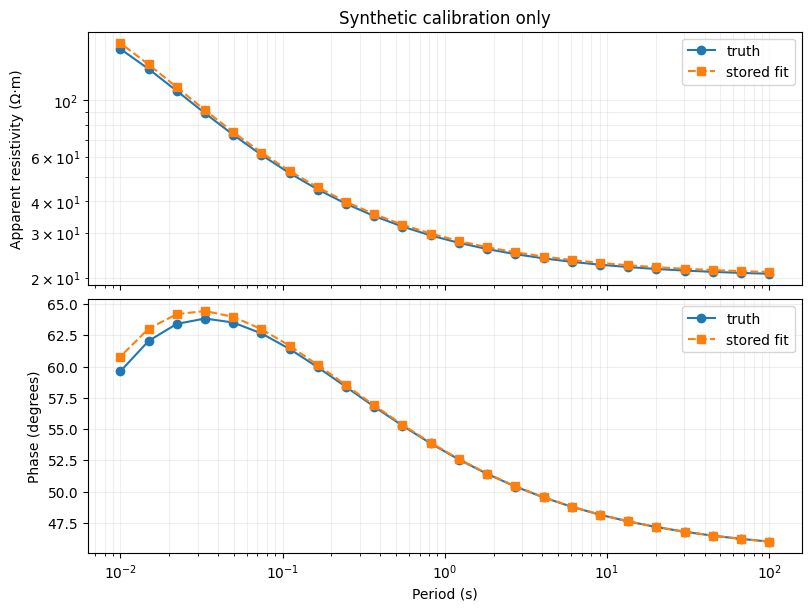

stored fitted rho Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Forward-project a stored fitted model and compare physical response curves.
import matplotlib.pyplot as plt
fit=cal["rows"][0]["model"]; other=curves(impedance(fit,h,f),f); T=1/np.asarray(f)
fig,ax=plt.subplots(2,1,figsize=(8,6),sharex=True,constrained_layout=True); ax[0].loglog(T,truth["apparent"],"o-",label="truth"); ax[0].loglog(T,other["apparent"],"s--",label="stored fit"); ax[1].semilogx(T,truth["phase"],"o-",label="truth"); ax[1].semilogx(T,other["phase"],"s--",label="stored fit")
ax[0].set_ylabel("Apparent resistivity (Ω·m)"); ax[1].set_ylabel("Phase (degrees)"); ax[1].set_xlabel("Period (s)"); [a.grid(True,which="both",alpha=.2) or a.legend() for a in ax]; ax[0].set_title("Synthetic calibration only"); plt.show(); print("stored fitted rho Ω·m",fit)

### Synthetic experiment: frequency coverage, noise and thickness trade-off

This additional **synthetic forward experiment** is separate from measured `cl061`. The repository layered-earth operator creates an exact three-layer response. Its implemented `identifiability` routine linearizes in log-resistivity while holding both thicknesses fixed. Compare the full frequency band with low-only and high-only subsets using identical model and per-component uncertainty. Singular values and local log-resistivity SD are conditional sensitivity diagnostics, not posterior uncertainty or proof of uniqueness.

A second forward-only perturbation increases the thickness and resistivity of the finite conductive layer together, approximately preserving conductance (`h/ρ`). Compare the complex response change with the declared noise scale. This familiar equivalence is approximate for a finite-frequency layered response. It demonstrates the fixed-thickness assumption; it is not a second inversion, a claim of recovered geology, or evidence about `cl061`.

In [3]:
# Synthetic experiment only: fixed-thickness local sensitivity across frequency windows.
f_syn=np.logspace(-3,2,60); h_syn=np.array([300.,700.]); rho_syn=np.array([80.,12.,250.])
z_syn=impedance(rho_syn,h_syn,f_syn)
sigma_syn=np.maximum(.03*np.abs(z_syn),1e-12) # SD of each independent real and imaginary component
bands={"full 0.001–100 Hz":np.ones(len(f_syn),dtype=bool),
       "low frequency ≤0.1 Hz":f_syn<=.1,
       "high frequency ≥1 Hz":f_syn>=1.}
diags={}
for label,mask in bands.items():
 d=em.identifiability(rho_syn,h_syn,f_syn,sigma_syn,mask)
 diags[label]=d
 print(label,"N=",int(mask.sum()),"effective rank=",d["effective_rank"],"/",d["parameter_count"],
       "singular values=",np.round(d["singular_values"],3),"local log-rho SD=",np.round(d["local_logrho_sd"],3),
       "unresolved layers=",d["unresolved_layers"],"status=",d["status"])
# Forward-only h/rho-preserving perturbation of the finite conductive layer.
rho_trade=np.array([rho_syn[0],rho_syn[1]*1.15,rho_syn[2]])
h_trade=np.array([h_syn[0],h_syn[1]*1.15])
z_trade=impedance(rho_trade,h_trade,f_syn)
whitened=np.abs(z_trade-z_syn)/sigma_syn
trade_wrms=float(np.sqrt(np.mean(whitened**2)/2))
print("Synthetic conductance trade-off; baseline h m=",h_syn,"rho ohm m=",rho_syn)
print("Perturbed h m=",h_trade,"rho ohm m=",rho_trade,"; whitened component WRMS=",trade_wrms)

full 0.001–100 Hz N= 60 effective rank= 3 / 3 singular values= [107.981  61.827  27.976] local log-rho SD= [0.036 0.011 0.015] unresolved layers= [] status= locally_resolved
low frequency ≤0.1 Hz N= 24 effective rank= 2 / 3 singular values= [71.098 31.793  0.1  ] local log-rho SD= [9.974 0.668 0.022] unresolved layers= [0] status= unresolved
high frequency ≥1 Hz N= 24 effective rank= 3 / 3 singular values= [64.944 27.966  6.79 ] local log-rho SD= [0.036 0.017 0.147] unresolved layers= [] status= locally_resolved
Synthetic conductance trade-off; baseline h m= [300. 700.] rho ohm m= [ 80.  12. 250.]
Perturbed h m= [300. 805.] rho ohm m= [ 80.   13.8 250. ] ; whitened component WRMS= 0.5429574698818997


### Plot the sensitivity and trade-off results

This cell visualizes the sensitivity ranks and parameter trade-off computed above; it does not fit or score field data.


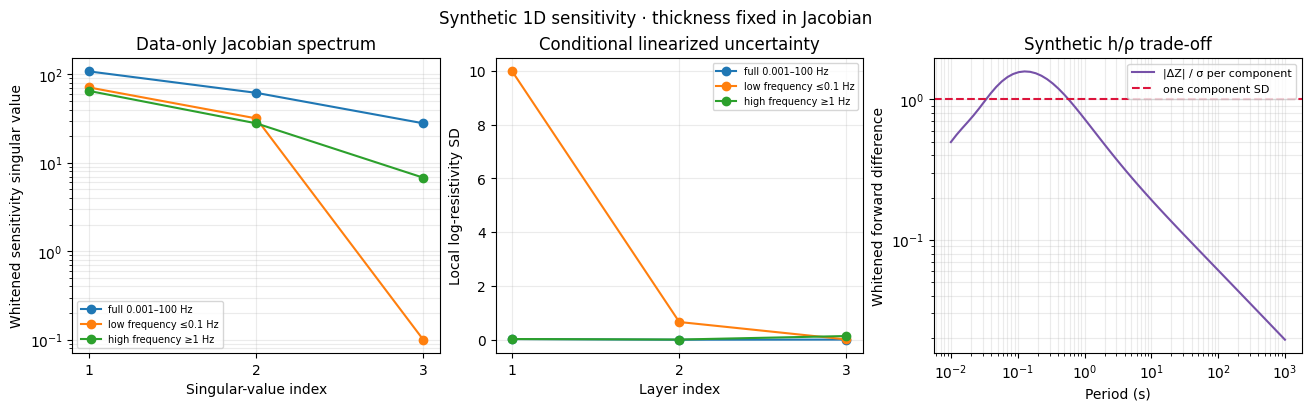

In [4]:
# Execute the documented experiment with the repository evidence.
import matplotlib.pyplot as plt
fig,ax=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for label,d in diags.items():
 s=np.asarray(d["singular_values"],float)
 ax[0].semilogy(np.arange(1,len(s)+1),s,marker="o",label=label)
 ax[1].plot(np.arange(1,len(rho_syn)+1),d["local_logrho_sd"],marker="o",label=label)
ax[0].set_xlabel("Singular-value index"); ax[0].set_ylabel("Whitened sensitivity singular value")
ax[0].set_title("Data-only Jacobian spectrum"); ax[1].set_xlabel("Layer index"); ax[1].set_ylabel("Local log-resistivity SD")
ax[1].set_title("Conditional linearized uncertainty")
for a in ax[:2]: a.set_xticks(np.arange(1,4)); a.grid(True,which="both",alpha=.25); a.legend(fontsize=7)
T=1/f_syn; ax[2].loglog(T,whitened,label="|ΔZ| / σ per component",color="#7651a8")
ax[2].axhline(1,color="crimson",ls="--",label="one component SD")
ax[2].set_xlabel("Period (s)"); ax[2].set_ylabel("Whitened forward difference"); ax[2].set_title("Synthetic h/ρ trade-off")
ax[2].grid(True,which="both",alpha=.25); ax[2].legend(fontsize=8)
fig.suptitle("Synthetic 1D sensitivity · thickness fixed in Jacobian"); plt.show()

## Summary

Conclusion is conditional on geometry, acquisition, noise model, split, parameterization and source rights. Preserve negative cases and name the next observation or control needed.

## References

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)